In [1]:
%load_ext autoreload
%autoreload 2   

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [3]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

from collections import OrderedDict
from pathlib import Path

import representation_spaces as rs
from data import GoEmotions
import part1
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools


## Data statistics

#TODO: write dataset description

#TODO: how to handle multi-class data points?

#TODO: merge dev and train for cross-validation?

In [4]:
ds = GoEmotions(drop_multi_labels=True, merge_train_dev=True)
ds.summary

,Total comments,Average n tokens,Median n tokens,Max tokens
train,40856.0,15.36,15.0,47.0
test,4590.0,15.26,15.0,37.0


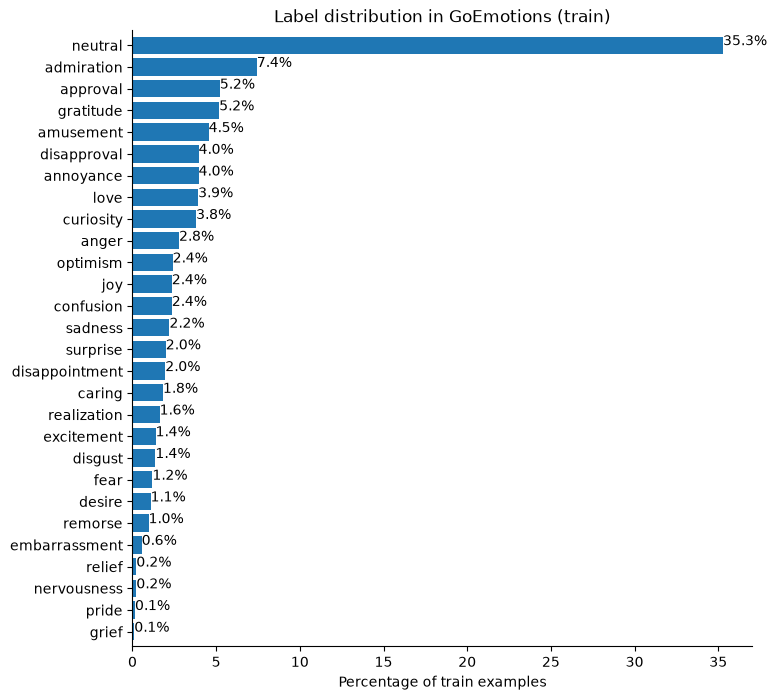

In [5]:
ds.plot_label_dist()

## Experiment

#TODO: description

In [6]:
from tokenizer import WordTokenizer

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

# True: train every config from scratch and save it to results_folder.
# False: load the tokenizer and models already saved in results_folder (no retraining).
TRAIN = True

min_frequency = 1
saved_tokenizers = sorted(results_folder.glob(f"word_tokenizer_vs_*_mf_{min_frequency}.json"))
if not TRAIN and saved_tokenizers:
    tokenizer = WordTokenizer().load(saved_tokenizers[0])
else:
    tokenizer = WordTokenizer().train(ds.train["text"].tolist(), vocab_size=None, min_frequency=min_frequency)
token_indicator_encoder = rs.TokenIndicator(tokenizer)
bag_of_words_encoder = rs.BagOfWords(tokenizer)
tfidf_encoder = rs.Tfidf(tokenizer).fit(ds.train["text"].tolist())

my_seeds = [0, 42, 99]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            pairs=list(zip(ds.train["text"], ds.train["label"])), 
            k=num_folds,
            seed=seed)
    )

emotions_outcome_space = part1.clslib.NamedClasses(names=ds.emotions)

In [7]:
tokenizer.save(f"{results_folder}/word_tokenizer_vs_{len(tokenizer.get_vocab())}_mf_{min_frequency}.json")

In [8]:
configs = {
    'logistic_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'svm-rbf_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'svm',
        'extra_args': {
            'svm_args': {
                'kernel': 'rbf',
                'C': 10,
                'gamma': 'scale',
            }
        }
    },
    'logistic_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'svm-rbf_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'svm',
        'extra_args': {
            'svm_args': {
                'kernel': 'rbf',
                'C': 10,
                'gamma': 'scale',
            }
        }
    },
    'logistic_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'svm-rbf_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'svm',
        'extra_args': {
            'svm_args': {
                'kernel': 'rbf',
                'C': 10,
                'gamma': 0.1,
            }
        }
    },
}

my_classifiers = OrderedDict()
for config in configs:
    my_classifiers[config] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/{config}/seed-{seed}"
        if TRAIN or not Path(run_folder).exists():   # also train configs that were never saved
            result = part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=emotions_outcome_space,
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                save_to=run_folder,
                **configs[config]['extra_args'],
            )
        else:
            result = part1.experiment.load_cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                load_from=run_folder,
            )
        my_classifiers[config].append(result)

  0%|          | 0/5 [00:00<?, ?it/s]

Logistic regression converged in 185 iterations.
Logistic regression converged in 224 iterations.
Logistic regression converged in 174 iterations.
Logistic regression converged in 171 iterations.
Logistic regression converged in 197 iterations.


  0%|          | 0/5 [00:00<?, ?it/s]

Logistic regression converged in 183 iterations.
Logistic regression converged in 191 iterations.
Logistic regression converged in 188 iterations.
Logistic regression converged in 153 iterations.
Logistic regression converged in 181 iterations.


  0%|          | 0/5 [00:00<?, ?it/s]

Logistic regression converged in 174 iterations.
Logistic regression converged in 170 iterations.
Logistic regression converged in 212 iterations.
Logistic regression converged in 182 iterations.
Logistic regression converged in 158 iterations.


... (243 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

SVM (rbf) trained with 29526 support vectors out of 32684 training examples.
SVM (rbf) trained with 29598 support vectors out of 32685 training examples.
SVM (rbf) trained with 29505 support vectors out of 32685 training examples.
SVM (rbf) trained with 29519 support vectors out of 32685 training examples.
SVM (rbf) trained with 29454 support vectors out of 32685 training examples.


  0%|          | 0/5 [00:00<?, ?it/s]

SVM (rbf) trained with 29543 support vectors out of 32684 training examples.
SVM (rbf) trained with 29555 support vectors out of 32685 training examples.
SVM (rbf) trained with 29539 support vectors out of 32685 training examples.
SVM (rbf) trained with 29571 support vectors out of 32685 training examples.
SVM (rbf) trained with 29481 support vectors out of 32685 training examples.


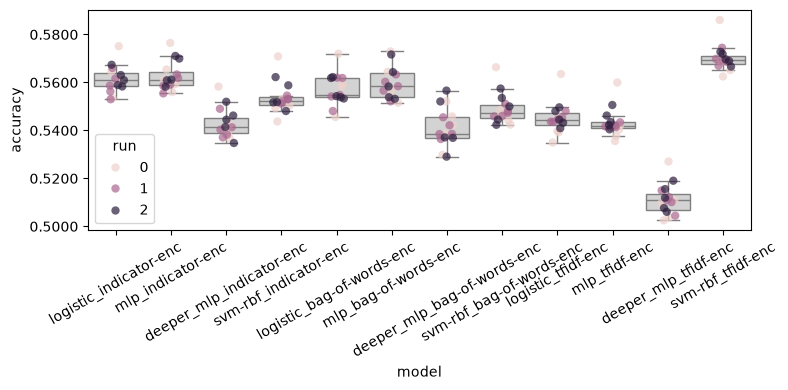

In [9]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [10]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

rope = 0.005
names = list(my_classifiers.keys())          # all nine configs
scores = {n: get_all_measurements_for(my_classifiers, n).flatten() for n in names}

rows = []
p_win = pd.DataFrame(np.nan, index=names, columns=names)   # P(row beats column)

for a, b in itertools.combinations(names, 2):
    posterior = part1.analysis.BenavoliCorrelatedT(
        scores[a],        # shape [num_runs * num_folds]
        scores[b],
        names=[a, b],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    rows.append({
        "A": a, "B": b,
        "P(A wins)": p_a, "P(Tie)": p_tie, "P(B wins)": p_b,
        "effect_size": posterior.effect_size,
    })
    p_win.loc[a, b] = p_a
    p_win.loc[b, a] = p_b

results_df = pd.DataFrame(rows)
print(results_df.round(4).to_string(index=False))

                          A                           B  P(A wins)  P(Tie)  P(B wins)  effect_size
     logistic_indicator-enc           mlp_indicator-enc     0.0000  0.9993     0.0006       1.3921
     logistic_indicator-enc    deeper_mlp_indicator-enc     1.0000  0.0000     0.0000     -12.2393
     logistic_indicator-enc       svm-rbf_indicator-enc     0.9065  0.0935     0.0000      -4.0017
     logistic_indicator-enc   logistic_bag-of-words-enc     0.1952  0.8048     0.0000      -4.7815
     logistic_indicator-enc        mlp_bag-of-words-enc     0.0230  0.9767     0.0002      -1.1912
     logistic_indicator-enc deeper_mlp_bag-of-words-enc     1.0000  0.0000     0.0000      -8.5696
     logistic_indicator-enc    svm-rbf_bag-of-words-enc     0.9995  0.0005     0.0000      -6.8916
     logistic_indicator-enc          logistic_tfidf-enc     1.0000  0.0000     0.0000     -10.2976
     logistic_indicator-enc               mlp_tfidf-enc     1.0000  0.0000     0.0000     -12.9895
     logis

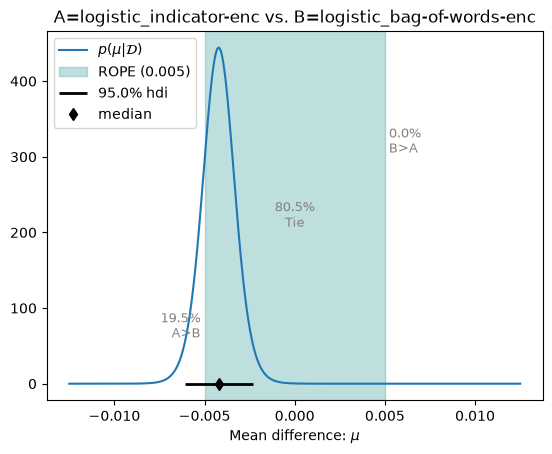

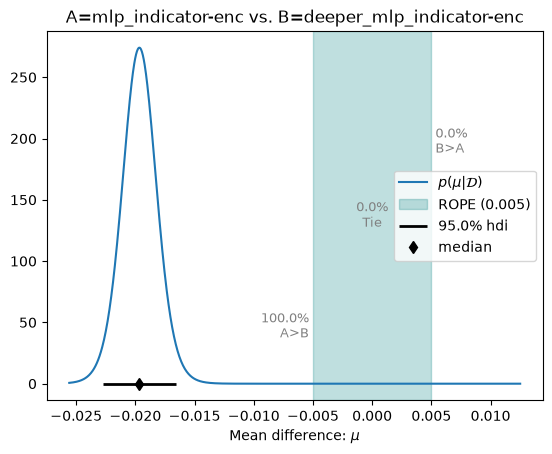

In [11]:
def plot_pair(a, b):
    return part1.analysis.BenavoliCorrelatedT(
        scores[a], scores[b], names=[a, b]
    ).plot(rope)

_ = plot_pair('logistic_indicator-enc', 'logistic_bag-of-words-enc')
_ = plot_pair('mlp_indicator-enc', 'deeper_mlp_indicator-enc')

In [12]:
from sklearn.metrics import accuracy_score, f1_score
import loglin, smlp, svm   # if this fails, try: from part1 import loglin, smlp, svm

test_texts = ds.test["text"].tolist()
y_test = np.array([int(l) for l in ds.test["label"]])

def fold_probs(config, model_path, texts):
    enc = configs[config]['encoder']
    if configs[config]['model_option'] == 'logistic':
        model = loglin.load(model_path)
        return loglin.predict_probs(texts, model, enc)
    if configs[config]['model_option'] == 'svm':
        # softmax over SVM decision scores: fine for averaging folds, NOT calibrated probabilities
        return svm.predict_probs(texts, svm.load(model_path), enc)
    model = smlp.load(model_path)
    return smlp.predict_probs(texts, model, enc, batch_size=512)

test_probs, test_preds, test_rows = {}, {}, []
for name in configs:
    paths = [p for run in my_classifiers[name] for p in run['models'].values()]   # all seeds x folds
    probs = np.mean([fold_probs(name, p, test_texts) for p in paths], axis=0)    # average over fold models
    test_probs[name] = probs
    test_preds[name] = probs.argmax(axis=1)
    test_rows.append({
        "system": name,
        "accuracy": accuracy_score(y_test, test_preds[name]),
        "macro_f1": f1_score(y_test, test_preds[name], average="macro"),
    })

test_df = pd.DataFrame(test_rows).sort_values("accuracy", ascending=False)
test_df.round(4)

,system,accuracy,macro_f1
11,svm-rbf_tfidf-enc,0.5747,0.3997
5,mlp_bag-of-words-enc,0.5710,0.3756
1,mlp_indicator-enc,0.5693,0.3648
0,logistic_indicator-enc,0.5684,0.4001
4,logistic_bag-of-words-enc,0.5660,0.3980
3,svm-rbf_indicator-enc,0.5584,0.3446
2,deeper_mlp_indicator-enc,0.5566,0.3014
6,deeper_mlp_bag-of-words-enc,0.5547,0.3082
9,mlp_tfidf-enc,0.5545,0.3620
7,svm-rbf_bag-of-words-enc,0.5512,0.3503
